# Customer Churn Prediction Using Machine Learning

## Project Objective

The goal of this project is to build a machine learning model that predicts whether a customer is likely to leave a telecommunications service provider.

Customer churn prediction is a **binary classification problem**, where each customer is classified as either having churned or having stayed.

This project will use the IBM Telco Customer Churn dataset to explore customer characteristics, identify patterns associated with churn, and compare two classification models: Logistic Regression and Random Forest.

## Project Goals

- Explore and visualize the customer dataset.
- Prepare numerical and categorical data for machine learning.
- Train and compare two classification models.
- Evaluate performance using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices.
- Investigate which features are most useful for predicting churn.
- Examine how changing the classification threshold affects predictions.

The final objective is to determine which model is most useful for identifying customers who may leave and to understand the limitations of its predictions.

In [46]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [47]:
# Import Dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [48]:
# Dataset Overview
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe(include="all").T)

print("\nMissing values per column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,0530-IJVDB,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values per column:


customerID          0
DeviceProtection    0
TotalCharges        0
MonthlyCharges      0
PaymentMethod       0
PaperlessBilling    0
Contract            0
StreamingMovies     0
StreamingTV         0
TechSupport         0
OnlineBackup        0
gender              0
OnlineSecurity      0
InternetService     0
MultipleLines       0
PhoneService        0
tenure              0
Dependents          0
Partner             0
SeniorCitizen       0
Churn               0
dtype: int64


Duplicate rows: 0


## Exploratory Data Analysis

Before training a machine learning model, it is important to understand the data and identify patterns that may be associated with customer churn.

The exploratory analysis will examine the distribution of churn, customer tenure, monthly charges, and contract types. These visualizations may reveal differences between customers who leave and those who remain.

The relationships identified during this stage are associations, not proof of causation.

Churn counts:


No     5174
Yes    1869
Name: Churn, dtype: int64


Churn proportions:


No     73.46
Yes    26.54
Name: Churn, dtype: float64

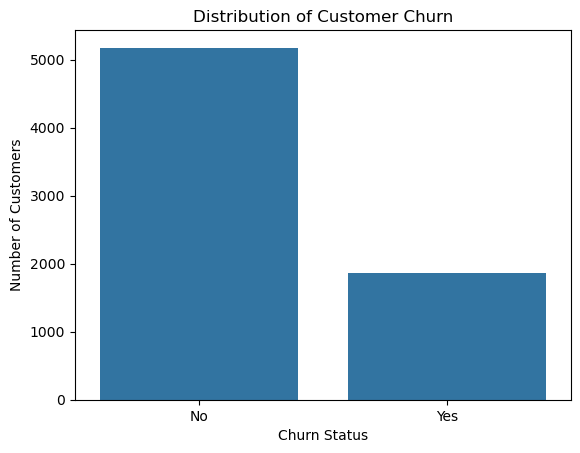

In [49]:
# Examining Churn Distribution
# (Determine whether more customers stayed than left.)
print("Churn counts:")
display(df["Churn"].value_counts())

print("\nChurn proportions:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=df, x="Churn")
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

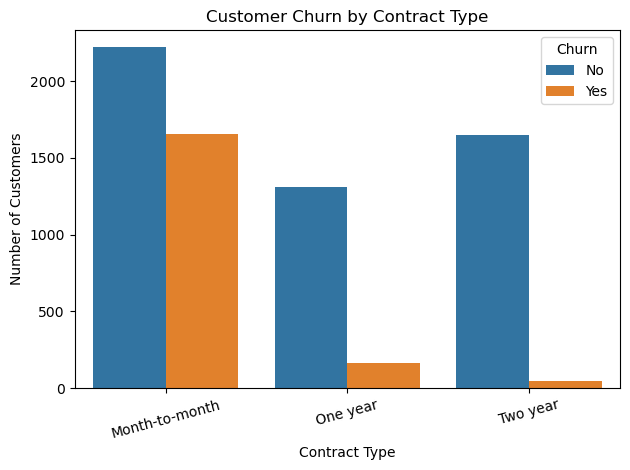

In [50]:
# Churn by Contact Type
# (Compare the number of churned and retained customers across contract types.)
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


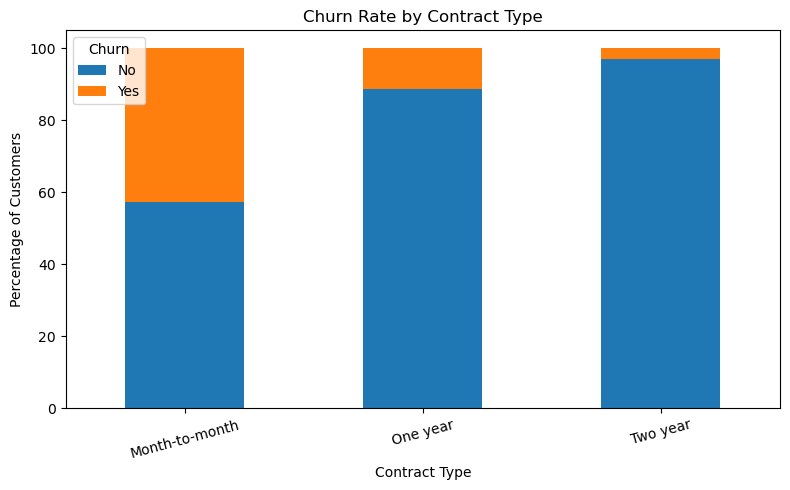

In [51]:
# Calculate churn rates by contract
# (Which contract type has the highest percentage of churned customers?)
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

display(contract_churn.round(2))

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

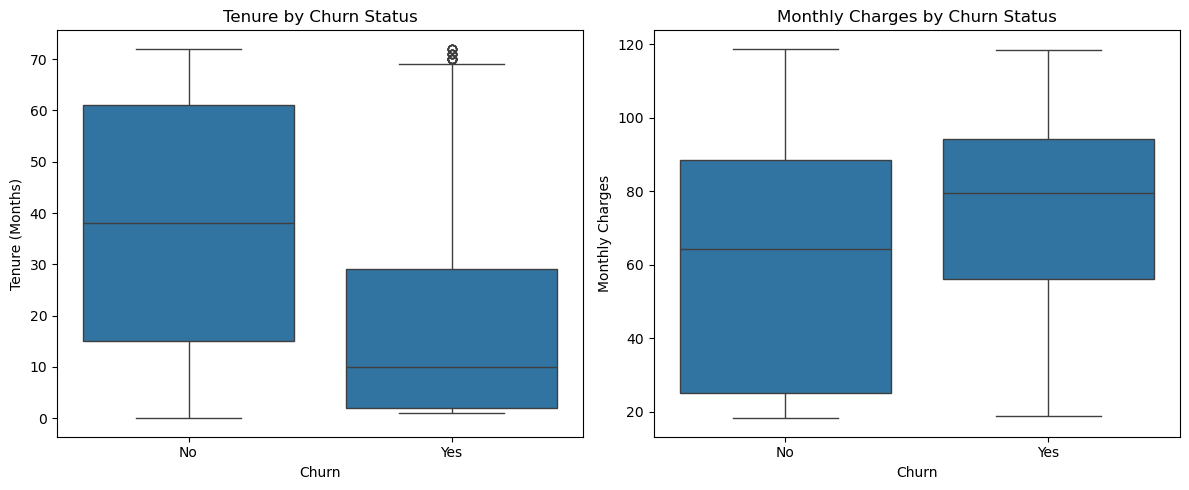

In [52]:
# Examine tenure and monthly charges
# (Check whether churned customers tend to have shorter tenures or different monthly charges.)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Tenure by Churn Status")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Tenure (Months)")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn Status")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

## Exploratory Data Analysis Findings

The dataset contains 7,043 customers and 21 columns, including customer information, service details, billing information, and the churn outcome. Of these customers, 1,869 (26.54%) churned, while 5,174 (73.46%) remained with the company. This indicates that churn is the minority class, so accuracy alone may not be sufficient to evaluate a predictive model.

Contract type showed a particularly strong association with churn. The churn rate was 42.71% for customers with month-to-month contracts, 11.27% for customers with one-year contracts, and 2.83% for customers with two-year contracts. Customers with month-to-month contracts therefore had a substantially higher observed churn rate than customers with longer contracts.

The analysis also examined customer tenure and monthly charges to investigate whether these characteristics differed between customers who churned and those who stayed. These visualizations help identify potential predictive relationships, although they do not establish causation.

Overall, the exploratory analysis suggests that contract type and customer-related characteristics may be useful for predicting churn. The class imbalance also highlights the importance of evaluating precision, recall, and F1-score alongside accuracy.

## Data Preparation

Machine learning models require data in a suitable numerical format. The target variable, `Churn`, will be converted into binary labels, with 1 representing customers who churned and 0 representing customers who stayed.

The customer ID will be excluded because it is an identifier rather than a meaningful customer characteristic. Numerical and categorical features will be processed separately. Missing numerical values will be imputed using the training-set median, and categorical values will be encoded using one-hot encoding.

The data will be divided into training, validation, and test sets. The training set will be used to fit models, the validation set will be used to compare models and experiment with decision thresholds, and the test set will be reserved for final evaluation.

In [53]:
# Clean and separate features

df = df.copy()

# Convert TotalCharges to numeric.
# Blank strings become missing values.
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Remove the customer identifier and separate the target.
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget counts:")
display(y.value_counts())

print("\nMissing TotalCharges values:", X["TotalCharges"].isna().sum())

Feature shape: (7043, 19)
Target shape: (7043,)

Target counts:


0    5174
1    1869
Name: Churn, dtype: int64


Missing TotalCharges values: 11


In [54]:
# Split cleaned data into training, validation, and test sets

# Hold out 20% for final testing.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split remaining 80% into training and validation sets.
# Final proportions: 60% training, 20% validation, 20% testing.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("\nTraining churn rate:", round(y_train.mean(), 3))
print("Validation churn rate:", round(y_val.mean(), 3))
print("Test churn rate:", round(y_test.mean(), 3))

Training rows: 4225
Validation rows: 1409
Test rows: 1409

Training churn rate: 0.265
Validation churn rate: 0.265
Test churn rate: 0.265


In [55]:
# Build processing pipeline

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nPreprocessing pipeline created successfully.")

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessing pipeline created successfully.


## Model Training

Two classification algorithms will be compared.

**Logistic Regression** provides a relatively simple baseline and estimates the probability of a customer churning.

**Random Forest Classifier** combines multiple decision trees and can learn more complex relationships between customer characteristics.

Both models will use the same training data and preprocessing pipeline. Their performance will initially be compared on the validation set rather than the test set.

In [56]:
# Train both of the listed models

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Random Forest trained successfully.


In [57]:
# Evaluate on the Validation Set

results = []

for name, model in models.items():
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.803,0.660,0.535,0.591,0.836
Random Forest,0.784,0.631,0.444,0.521,0.812


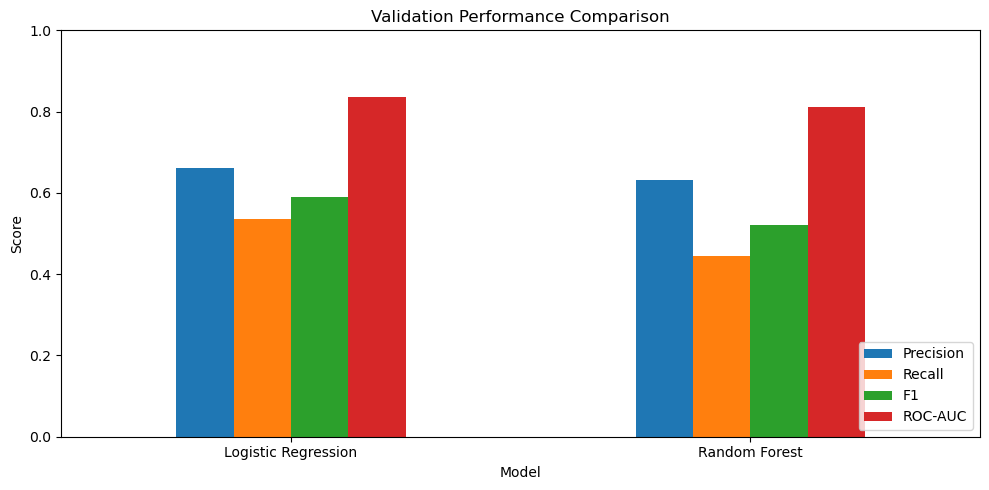

In [58]:
# Visually compare the validation metrics

results_df[["Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Validation Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [59]:
# Select the best validation model

best_model_name = results_df["F1"].idxmax()
best_model = models[best_model_name]

print("Selected model:", best_model_name)
print("Validation F1-score:", round(results_df.loc[best_model_name, "F1"], 3))

Selected model: Logistic Regression
Validation F1-score: 0.591


## Model Comparison Findings

Logistic Regression outperformed Random Forest on the validation set across the reported evaluation metrics. Logistic Regression achieved an accuracy of 0.803, precision of 0.660, recall of 0.535, F1-score of 0.591, and ROC-AUC of 0.836. Random Forest achieved an accuracy of 0.784, precision of 0.631, recall of 0.444, F1-score of 0.521, and ROC-AUC of 0.812.

The results indicate that Logistic Regression was more effective at distinguishing churners from non-churners on this dataset, while also identifying a greater proportion of actual churners at the default threshold. Although Random Forest can model complex relationships, it did not outperform the simpler Logistic Regression model in this experiment.

Based on its stronger validation performance, Logistic Regression was selected for the final model evaluation. This demonstrates that a more complex model does not necessarily provide better predictive performance.

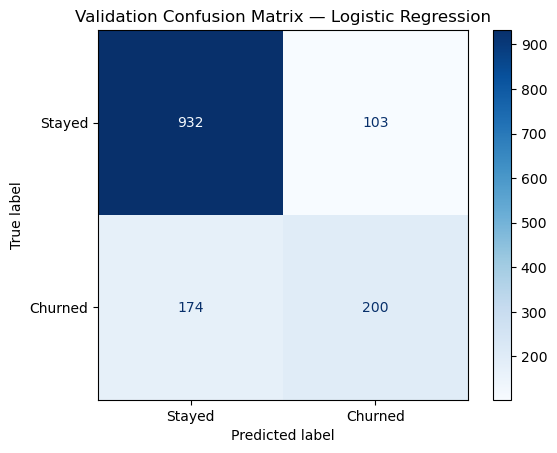

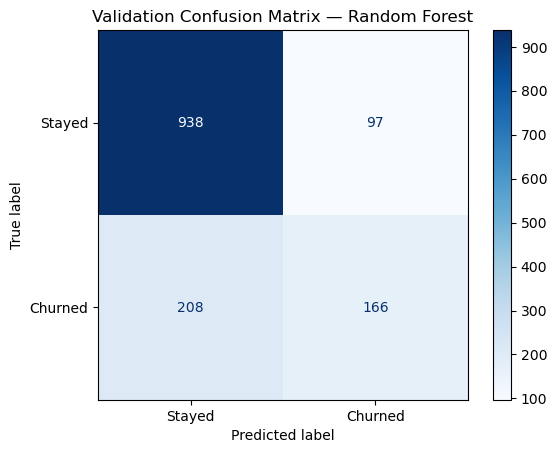

In [60]:
# Examine confusion matrices on the chosen validation set
# Look for: True neg, True pos, False neg, False pos
for name, model in models.items():
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        model.predict(X_val),
        display_labels=["Stayed", "Churned"],
        cmap="Blues"
    )

    plt.title(f"Validation Confusion Matrix — {name}")
    plt.show()

In [61]:
# Experiment with decision thresholds
# Default is 0.5, reducing increases recall, but lowers precision

val_probabilities = best_model.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60]:
    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results).set_index("Threshold")
display(threshold_df.round(3))

,Precision,Recall,F1
Threshold,,,
0.3,0.537,0.749,0.626
0.4,0.594,0.642,0.617
0.5,0.660,0.535,0.591
0.6,0.710,0.380,0.495


## Decision Threshold Selection

The validation results showed that changing the classification threshold affected the balance between precision and recall. At the default threshold of 0.50, Logistic Regression achieved a precision of 0.660, a recall of 0.535, and an F1-score of 0.591.

Lowering the threshold to 0.30 increased recall to 0.749 and improved the F1-score to 0.626, although precision decreased to 0.537. This means the model identified a greater proportion of customers who actually churned, but a larger proportion of its churn predictions were false positives.

Based on the improved validation F1-score and the objective of identifying more potential churners, a threshold of 0.30 was selected. This threshold prioritizes churn detection over minimizing false alarms, which may be appropriate if missing a customer who is about to leave is costly.

The threshold was selected using the validation data, and the test set was reserved for the final evaluation. The final test results can therefore be used to assess how well this decision performs on previously unseen customers.

In [62]:
# Choose a final threshold based on validation results (EDIT)
chosen_threshold = 0.30

print("Selected model:", best_model_name)
print("Chosen decision threshold:", chosen_threshold)

Selected model: Logistic Regression
Chosen decision threshold: 0.3


In [63]:
# Do a final evaluation of the test set

test_probabilities = best_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= chosen_threshold
).astype(int)

final_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities)
}

print("Selected model:", best_model_name)
print("Decision threshold:", chosen_threshold)

display(pd.DataFrame(
    [final_metrics],
    index=[best_model_name]
).round(3))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

Selected model: Logistic Regression
Decision threshold: 0.3


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.755,0.527,0.754,0.62,0.843



Classification report:
              precision    recall  f1-score   support

      Stayed       0.89      0.76      0.82      1035
     Churned       0.53      0.75      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.76      0.77      1409



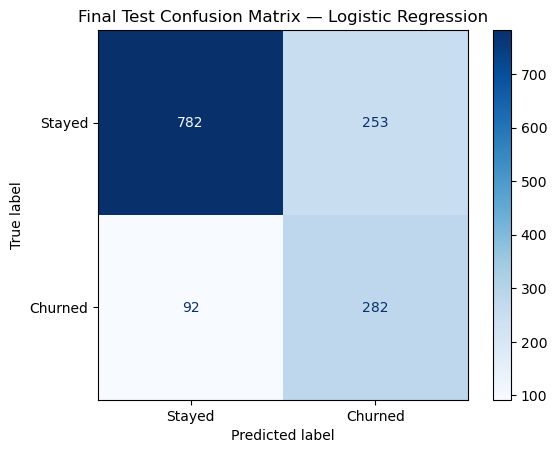

In [64]:
# Plot on the final confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title(f"Final Test Confusion Matrix — {best_model_name}")
plt.show()

## Final Test Evaluation

The selected Logistic Regression model was evaluated on the test dataset using a decision threshold of 0.30. It achieved an accuracy of 75.5%, precision of 52.7%, recall of 75.4%, an F1-score of 0.620, and a ROC-AUC of 0.843.

The confusion matrix showed that the model correctly identified 282 of the 374 customers who churned, while missing 92 actual churners. It also incorrectly flagged 253 customers who stayed as potential churners.

These results suggest that the model is reasonably effective at identifying customers who may leave, particularly when recall is prioritized. However, its relatively moderate precision means that many flagged customers would not actually churn. A company would need to consider the cost of these false positives when deciding whether to use the model for retention campaigns.

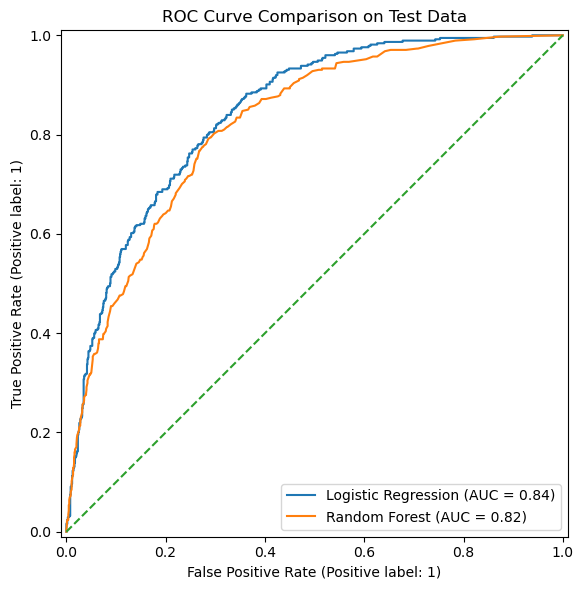

In [65]:
# Plot ROC curves

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        ax=ax,
        name=name
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random baseline"
)

ax.set_title("ROC Curve Comparison on Test Data")
plt.tight_layout()
plt.show()

## Interpreting the Logistic Regression Model

To better understand the selected model, the Logistic Regression coefficients were examined to identify which features were associated with higher or lower predicted odds of customer churn. Positive coefficients indicate an increase in predicted churn odds, while negative coefficients indicate a decrease, holding other features constant.

The coefficient analysis provides insight into how the selected model uses customer characteristics to make predictions. These relationships should not be interpreted as evidence of causation, and coefficient magnitudes must be considered in relation to feature scaling and encoding.

In [69]:

# Get feature names from the fitted preprocessing pipeline
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

# Get coefficients from the fitted Logistic Regression classifier
coefficients = best_model.named_steps["classifier"].coef_[0]

# Create a table of feature coefficients
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Display the 10 strongest positive coefficients
display(
    coefficient_df.sort_values(
        by="Coefficient",
        ascending=False
    ).head(10)
)

,Feature,Coefficient
36,cat__Contract_Month-to-month,0.660215
3,num__TotalCharges,0.573744
16,cat__InternetService_Fiber optic,0.524309
43,cat__PaymentMethod_Electronic check,0.178668
32,cat__StreamingTV_Yes,0.165628
18,cat__OnlineSecurity_No,0.155977
27,cat__TechSupport_No,0.138113
35,cat__StreamingMovies_Yes,0.122109
14,cat__MultipleLines_Yes,0.064710
0,num__SeniorCitizen,0.059422


## Logistic Regression Coefficient Results

The Logistic Regression coefficient analysis identified month-to-month contracts as the feature with the largest positive coefficient (0.660), followed by `TotalCharges` (0.574) and fiber-optic internet service (0.524). Other features with positive coefficients included electronic check payments, streaming TV, the absence of online security, and the absence of tech support.

These positive coefficients indicate that the corresponding features are associated with higher predicted odds of customer churn, holding other features constant. In particular, the strong positive coefficient for month-to-month contracts suggests that contract type plays an important role in the model's churn predictions. This is consistent with the exploratory analysis, which found a substantially higher churn rate among customers with month-to-month contracts.

However, these coefficients should be interpreted carefully. Numeric and categorical features are processed differently, so coefficient magnitudes are not always directly comparable. Additionally, positive coefficients represent associations learned by the model and do not prove that these features cause customers to churn.

## Feature Importance Analysis

After evaluating the models and interpreting the logistic regression model, the next step is to investigate which customer characteristics are most useful for predicting churn.

The Random Forest model provides feature-importance scores that summarize how much each encoded feature contributes to reducing impurity across the trees. These scores can help identify patterns that the model relies on when making predictions.

However, feature importance does not establish causation, and correlated features can affect how importance is distributed between variables.

In [70]:
# Calculate Random Forest feature importance

rf_model = models["Random Forest"]

feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15).round(4))

,Feature,Importance
3,num__TotalCharges,0.1349
1,num__tenure,0.1287
2,num__MonthlyCharges,0.1197
36,cat__Contract_Month-to-month,0.0757
38,cat__Contract_Two year,0.0398
18,cat__OnlineSecurity_No,0.0393
27,cat__TechSupport_No,0.0341
43,cat__PaymentMethod_Electronic check,0.0274
16,cat__InternetService_Fiber optic,0.0273
21,cat__OnlineBackup_No,0.0178


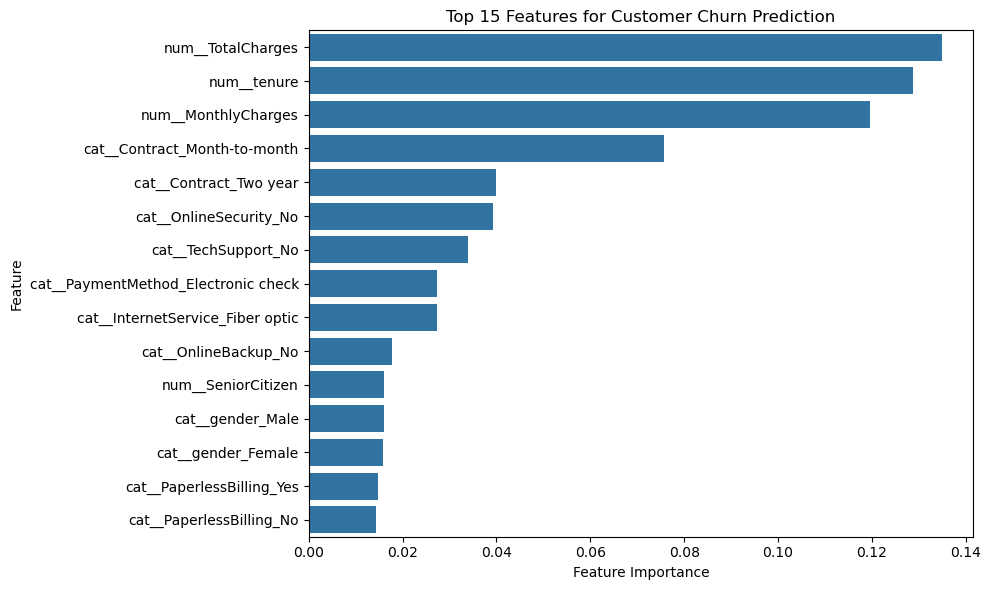

In [71]:
# Visualize most significant features

top_features = importance_df.head(15).sort_values(
    "Importance",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features for Customer Churn Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Feature Importance Findings

The Random Forest feature-importance analysis identified `TotalCharges`, `tenure`, and `MonthlyCharges` as the three most important features, with importance scores of approximately 0.135, 0.129, and 0.120, respectively. Contract type was also influential, particularly the month-to-month contract category, which had an importance score of approximately 0.076.

These results suggest that billing history, customer tenure, monthly charges, and contract arrangements provided useful information for the Random Forest model when predicting churn. The findings are consistent with the exploratory analysis, which showed substantially higher churn rates among customers with month-to-month contracts.

However, these importance scores describe the Random Forest model, not the selected Logistic Regression model. They do not establish that these features cause churn, and related variables such as tenure and total charges may share predictive information.

## Project Conclusion

This project used machine learning to predict customer churn using the IBM Telco Customer Churn dataset, which contains 7,043 customer records. Exploratory data analysis revealed that 26.54% of customers had churned, with particularly high churn among customers on month-to-month contracts (42.71%), compared with 11.27% for one-year contracts and 2.83% for two-year contracts.

Logistic Regression outperformed Random Forest on the validation set, achieving an F1-score of 0.591 and a ROC-AUC of 0.836 at the default classification threshold. The decision-threshold experiment showed that lowering the threshold from 0.50 to 0.30 increased recall from 0.535 to 0.749 and improved the F1-score to 0.626, although precision decreased.

On the final test set, the selected Logistic Regression model with a threshold of 0.30 achieved 75.5% accuracy, 52.7% precision, 75.4% recall, an F1-score of 0.620, and a ROC-AUC of 0.843. It correctly identified 282 of the 374 customers who churned, demonstrating its ability to identify many potential churners, while also producing 253 false-positive predictions.

The Logistic Regression coefficient analysis provided additional insight into the selected model's predictions. Month-to-month contracts had the largest positive coefficient (0.660), followed by `TotalCharges` (0.574) and fiber-optic internet service (0.524). Other positively associated features included electronic check payments, streaming services, and the absence of online security or tech support. These positive coefficients indicate higher predicted odds of churn, holding other features constant. The findings reinforce the importance of contract type and customer service characteristics in the model's predictions, although these associations do not establish causation.

The Random Forest feature-importance analysis identified `TotalCharges`, `tenure`, `MonthlyCharges`, and contract type as useful predictive features. These findings suggest that customer billing history and service arrangements contain information relevant to churn prediction, although feature importance does not establish causation.

Overall, this project demonstrated how classification models can be compared and evaluated, how decision thresholds influence prediction outcomes, and how machine learning can support customer-retention decisions. The model could help a company identify customers for retention efforts, but its moderate precision means that some flagged customers would not actually leave. Further improvements could include hyperparameter tuning, cross-validation, and evaluating the financial costs of false positives and false negatives. The findings may also not generalize to other telecommunications companies or customer populations.

## Relevant Skills

Through this project, I learned how to build and evaluate classification models to predict customer churn. I gained experience comparing Logistic Regression and Random Forest, interpreting evaluation metrics such as precision, recall, F1-score, and ROC-AUC, and adjusting classification thresholds to balance missed churners against false-positive predictions. I also learned how to interpret model coefficients and feature importance to better understand which customer characteristics are useful for predicting churn. Overall, this project improved my understanding of the machine learning workflow and how predictive models can support real-world business decisions.